# Predicting Urban Heat Island Severity in Perth

Classifying grid cells across the Perth metropolitan area into low, moderate or severe Urban Heat Island severity using Python, SQL and scikit-learn.


## 1. Load Data
Load the labelled (5000 rows, has target) and unseen (500 rows, no target) tables from the SQLite database.

In [19]:
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

conn = sqlite3.connect('data/uhi_data.sqlite')
df_labelled = pd.read_sql_query("SELECT * FROM labelled", conn)
df_unseen = pd.read_sql_query("SELECT * FROM unseen", conn)
conn.close()
random_state=42

print(df_labelled.shape, df_unseen.shape)

(5000, 32) (500, 31)


## 2. Explore Data
Check structure, missing values, duplicates, correlations, and categorical values to identify data quality issues.

In [20]:
pd.options.display.max_columns = 120

In [21]:
df_labelled.info()
df_labelled.duplicated().sum()
df_unseen.duplicated().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 32 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   index                         5000 non-null   int64  
 1   impervious_surface_pct        5000 non-null   float64
 2   land_use_zone                 5000 non-null   object 
 3   rainfall_annual_mm            5000 non-null   float64
 4   public_transport_score        5000 non-null   float64
 5   surface_albedo_index          5000 non-null   float64
 6   age_of_dwellings_years        5000 non-null   float64
 7   street_lighting_density       5000 non-null   float64
 8   road_density_km_per_km2       5000 non-null   float64
 9   number_of_community_centres   497 non-null    float64
 10  suburb_age_category           5000 non-null   object 
 11  avg_land_value_per_sqm        5000 non-null   float64
 12  council_area                  5000 non-null   object 
 13  bui

np.int64(0)

In [22]:
df_labelled.isnull().sum()

index                              0
impervious_surface_pct             0
land_use_zone                      0
rainfall_annual_mm                 0
public_transport_score             0
surface_albedo_index               0
age_of_dwellings_years             0
street_lighting_density            0
road_density_km_per_km2            0
number_of_community_centres     4503
suburb_age_category                0
avg_land_value_per_sqm             0
council_area                       0
building_density_per_ha            0
crime_rate_index                   0
avg_commute_time_min               0
green_infrastructure_score         0
avg_building_height_m            992
population_density_per_km2         0
household_solar_panel_pct          0
distance_to_cbd_km                 0
avg_household_size                 0
park_area_within_500m_ha           0
roof_type                          0
median_household_income            0
wind_exposure_category             0
tree_canopy_pct                  251
b

In [23]:
df_labelled.describe()

,index,impervious_surface_pct,rainfall_annual_mm,public_transport_score,surface_albedo_index,age_of_dwellings_years,street_lighting_density,road_density_km_per_km2,number_of_community_centres,avg_land_value_per_sqm,building_density_per_ha,crime_rate_index,avg_commute_time_min,green_infrastructure_score,avg_building_height_m,population_density_per_km2,household_solar_panel_pct,distance_to_cbd_km,avg_household_size,park_area_within_500m_ha,median_household_income,tree_canopy_pct,distance_to_coast_km,number_of_schools_within_2km,nearest_hospital_distance_km
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,497.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,4008.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,4749.000000,5000.000000,5000.000000,5000.000000
mean,2499.500000,52.543935,722.353147,5.011187,0.196698,49.450474,22.454961,13.576604,1.525151,3242.758963,60.178089,50.683313,35.108745,50.384890,11.523066,3145.376698,44.538510,19.946968,2.981548,7.457131,107239.916299,30.040816,19.929377,3.015200,9.967717
std,1443.520003,24.936801,137.533637,2.906285,0.089324,28.980490,10.126835,6.656727,1.247526,1601.855769,37.044354,29.049084,14.536746,28.925713,6.459213,1665.350202,25.986319,11.624471,0.923672,4.304024,42096.166819,17.421262,11.556727,1.755444,5.732824
min,0.000000,10.003490,367.935392,0.000652,-0.054117,0.014947,5.002335,2.011885,0.000000,502.324069,-35.949948,0.037616,10.033888,0.084735,3.000000,201.337587,0.002166,0.004849,0.609610,0.000394,35024.369463,0.043725,0.001752,0.000000,0.001147
25%,1249.750000,30.738977,608.448511,2.523610,0.135900,24.444530,13.829088,7.726800,1.000000,1806.109224,29.505543,25.307148,22.398948,25.477861,6.073690,1716.436685,22.415225,9.809690,2.205906,3.747242,70721.963974,15.090871,9.925542,2.000000,5.046754
50%,2499.500000,52.316578,721.121335,5.006923,0.195650,48.940302,22.395898,13.679274,1.000000,3301.079519,60.500027,51.395117,35.220118,50.186160,10.848140,3169.759766,44.369238,20.257495,2.984387,7.499281,107546.605289,29.556267,19.954669,3.000000,9.896543
75%,3749.250000,73.939069,837.566251,7.609868,0.250830,74.396258,31.295492,19.395242,2.000000,4612.891832,91.041831,75.685222,47.923151,75.418935,15.924106,4598.691402,66.789660,29.774610,3.738071,11.119744,143762.554869,45.373594,29.964600,4.000000,15.066933
max,4999.000000,94.981934,1084.063961,9.997393,0.504626,99.976031,39.995307,24.992019,5.000000,5998.759741,155.640964,99.992507,59.967886,99.909351,32.948888,5998.063408,89.958162,39.983486,5.393048,14.996442,179917.268219,59.999291,39.989280,8.000000,19.993426


In [24]:
df_labelled.corr(numeric_only=True)

,index,impervious_surface_pct,rainfall_annual_mm,public_transport_score,surface_albedo_index,age_of_dwellings_years,street_lighting_density,road_density_km_per_km2,number_of_community_centres,avg_land_value_per_sqm,building_density_per_ha,crime_rate_index,avg_commute_time_min,green_infrastructure_score,avg_building_height_m,population_density_per_km2,household_solar_panel_pct,distance_to_cbd_km,avg_household_size,park_area_within_500m_ha,median_household_income,tree_canopy_pct,distance_to_coast_km,number_of_schools_within_2km,nearest_hospital_distance_km
index,1.000000,0.004621,-0.001043,-0.020653,0.007595,-0.034718,-0.007758,-0.009808,0.014861,-0.002739,-0.009659,0.014102,-0.007361,0.001960,-0.030032,-0.015245,-0.004343,0.011431,-0.008315,0.017179,0.005502,0.009702,0.009312,0.003178,0.017274
impervious_surface_pct,0.004621,1.000000,0.027886,0.023474,0.007678,0.004559,0.174589,0.347092,-0.072748,-0.007525,0.597774,-0.005520,0.007343,-0.210020,-0.007714,0.308351,-0.004554,-0.020914,-0.016114,-0.028776,-0.009563,-0.003444,0.016320,-0.011766,-0.010361
rainfall_annual_mm,-0.001043,0.027886,1.000000,-0.019355,-0.021449,0.008408,-0.010742,0.002261,0.060897,-0.003264,0.006676,0.051859,0.006018,-0.025937,0.013796,-0.007748,0.008385,-0.006504,-0.021327,-0.001592,-0.009351,-0.009105,0.016336,0.003511,-0.029971
public_transport_score,-0.020653,0.023474,-0.019355,1.000000,-0.017065,0.012858,0.029240,0.021578,0.024435,0.016371,0.026897,-0.007791,-0.275193,-0.003006,0.017665,0.011126,0.018218,-0.498437,-0.024555,-0.024604,-0.006672,0.003628,-0.009620,-0.003915,0.029084
surface_albedo_index,0.007595,0.007678,-0.021449,-0.017065,1.000000,-0.003570,0.005474,-0.007832,-0.016922,-0.002101,0.000351,0.009935,0.020384,-0.002745,-0.476478,0.004164,-0.012798,0.029835,-0.001921,0.027867,0.004356,0.010517,0.005410,0.000447,-0.014323
age_of_dwellings_years,-0.034718,0.004559,0.008408,0.012858,-0.003570,1.000000,0.007384,-0.002294,0.010611,-0.015883,-0.002829,-0.009526,-0.001227,0.021854,-0.003243,0.013432,0.007962,0.010674,0.010317,0.014788,0.015086,0.022625,-0.002413,-0.001706,-0.016695
street_lighting_density,-0.007758,0.174589,-0.010742,0.029240,0.005474,0.007384,1.000000,0.492825,-0.072725,0.008673,0.222646,0.007193,0.003303,-0.035106,0.027892,0.106829,0.018117,-0.017189,-0.009187,-0.022515,-0.017219,0.005505,-0.001406,0.007871,-0.007327
road_density_km_per_km2,-0.009808,0.347092,0.002261,0.021578,-0.007832,-0.002294,0.492825,1.000000,-0.063485,0.009028,0.453673,-0.008606,0.013204,-0.057012,0.008590,0.220250,0.000037,-0.022740,-0.003866,-0.017199,0.004856,0.007601,0.006463,0.002844,-0.002865
number_of_community_centres,0.014861,-0.072748,0.060897,0.024435,-0.016922,0.010611,-0.072725,-0.063485,1.000000,-0.040480,-0.039541,0.009535,0.008665,-0.014609,0.058005,0.052243,0.011073,0.020340,-0.039044,-0.000077,-0.073083,-0.032817,0.017752,0.009236,0.054481
avg_land_value_per_sqm,-0.002739,-0.007525,-0.003264,0.016371,-0.002101,-0.015883,0.008673,0.009028,-0.040480,1.000000,-0.013861,-0.019461,-0.005294,-0.016934,-0.020403,-0.011829,0.015719,-0.026772,-0.000598,-0.009222,-0.009807,-0.029359,-0.560877,0.002952,0.016396


In [25]:
corr_matrix = df_labelled.drop(columns='index').corr(numeric_only=True)
corr_pairs = corr_matrix.unstack()
corr_pairs = corr_pairs[(corr_pairs.abs() > 0.7) & (corr_pairs.abs() < 1.0)]
corr_pairs.sort_values(ascending=False)

Series([], dtype: float64)

In [26]:
for col in df_labelled.select_dtypes(include='object').columns:
    print(col, df_labelled[col].unique())
df_labelled['uhi_severity_class'].value_counts()

land_use_zone ['mixed_use' 'commercial' 'residential_low_density'
 'residential_high_density' 'industrial' 'open_space']
suburb_age_category ['middle_aged' 'established' 'new_estate']
council_area ['Armadale' 'Swan' 'Stirling' 'Joondalup' 'Belmont' 'Cockburn' 'Vincent'
 'belmont' 'stirling' 'swan' 'armadale' 'cockburn' 'joondalup' 'vincent']
roof_type ['concrete' 'tile' 'dark_metal' 'light_metal']
wind_exposure_category ['exposed' 'sheltered' 'moderate']
bin_collection_day ['Fri']
uhi_severity_class ['severe' 'low' 'moderate']


uhi_severity_class
moderate    2085
low         1999
severe       916
Name: count, dtype: int64

### 2.1 Check Physically Implausible Values
Compare min/max of numeric columns against the data dictionary. Found negative values in surface_albedo_index and building_density_per_ha, and near-zero values in avg_household_size — all physically impossible.

In [27]:
print("Negative albedo:", (df_labelled['surface_albedo_index'] < 0).sum())
print("Negative building density:", (df_labelled['building_density_per_ha'] < 0).sum())
print("Household size < 1:", (df_labelled['avg_household_size'] < 1).sum())

df_labelled['uhi_severity_class'].value_counts()

Negative albedo: 45
Negative building density: 76
Household size < 1: 33


uhi_severity_class
moderate    2085
low         1999
severe       916
Name: count, dtype: int64

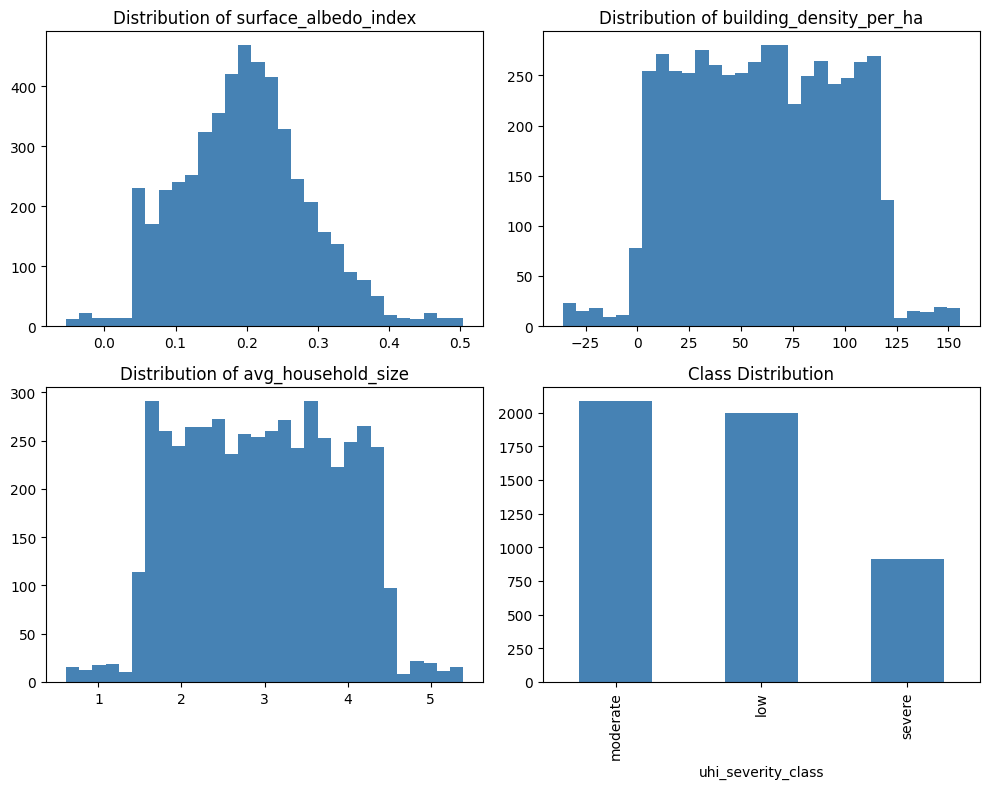

In [28]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

axes[0,0].hist(df_labelled['surface_albedo_index'], bins=30, color='steelblue')
axes[0,0].set_title('Distribution of surface_albedo_index')

axes[0,1].hist(df_labelled['building_density_per_ha'], bins=30, color='steelblue')
axes[0,1].set_title('Distribution of building_density_per_ha')

axes[1,0].hist(df_labelled['avg_household_size'], bins=30, color='steelblue')
axes[1,0].set_title('Distribution of avg_household_size')

df_labelled['uhi_severity_class'].value_counts().plot(kind='bar', ax=axes[1,1], color='steelblue')
axes[1,1].set_title('Class Distribution')

plt.tight_layout()
plt.savefig('distributions.png', dpi=150)
plt.show()

## 3. Data Preparation
Clean and transform the data. All fitting (imputer, encoder, scaler) is done on labelled only, then applied to unseen, to avoid data leakage.

In [29]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, FunctionTransformer, OneHotEncoder

# 3.1 Mark physically implausible values as NaN
def mark_implausible_values(df):
    df = df.copy()
    df.loc[df['surface_albedo_index'] < 0, 'surface_albedo_index'] = np.nan
    df.loc[df['building_density_per_ha'] < 0, 'building_density_per_ha'] = np.nan
    df.loc[df['avg_household_size'] < 1, 'avg_household_size'] = np.nan
    return df

def fix_council_area_format(df):
    df = df.copy()
    df['council_area'] = df['council_area'].astype(str).str.lower()
    return df

implausible_transformer = FunctionTransformer(mark_implausible_values)
council_format_transformer = FunctionTransformer(fix_council_area_format)

add_features = Pipeline(steps=[
    ('mark_implausible', implausible_transformer),
    ('fix_council_format', council_format_transformer)
])

# 3.2 Column groups
unused_features = ['index', 'number_of_community_centres', 'bin_collection_day']

numerical_features = [
    'impervious_surface_pct', 'rainfall_annual_mm', 'public_transport_score',
    'surface_albedo_index', 'age_of_dwellings_years', 'street_lighting_density',
    'road_density_km_per_km2', 'avg_land_value_per_sqm', 'building_density_per_ha',
    'crime_rate_index', 'avg_commute_time_min', 'green_infrastructure_score',
    'avg_building_height_m', 'population_density_per_km2', 'household_solar_panel_pct',
    'distance_to_cbd_km', 'avg_household_size', 'park_area_within_500m_ha',
    'median_household_income', 'tree_canopy_pct', 'distance_to_coast_km',
    'number_of_schools_within_2km', 'nearest_hospital_distance_km'
]

categorical_features = [
    'land_use_zone', 'suburb_age_category', 'council_area', 'roof_type', 'wind_exposure_category'
]

# 3.3 Transformers
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('drop_features', 'drop', unused_features),
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features),
    ],
    remainder='drop'
)

print("successfully")

successfully


In [30]:
df_check = df_labelled.copy()
df_check['council_area'] = df_check['council_area'].astype(str).str.lower()
print(df_check.drop(columns='index').drop(columns='uhi_severity_class').duplicated().sum())


50


In [31]:
cols_check = [c for c in df_labelled.columns if c not in ['index', 'uhi_severity_class']]

df_check = df_labelled[cols_check].copy()
df_check['council_area'] = df_check['council_area'].astype(str).str.lower()

merged = df_check.merge(df_check)
print(merged.shape[0] - len(df_check))

102


In [32]:
dup_mask = df_check.duplicated(keep=False)
dup_rows = df_check[dup_mask]

print("Rows flagged as duplicate:", dup_mask.sum())
print(dup_rows[['surface_albedo_index','building_density_per_ha','avg_household_size',
                'tree_canopy_pct','avg_building_height_m']].isna().sum())

Số dòng bị đánh dấu duplicate: 99
surface_albedo_index        0
building_density_per_ha     0
avg_household_size          0
tree_canopy_pct             6
avg_building_height_m      12
dtype: int64


In [33]:
df_labelled_lower = df_labelled.copy()
df_labelled_lower['council_area'] = df_labelled_lower['council_area'].astype(str).str.lower()

cols_for_dup_check = [c for c in df_labelled.columns if c not in ['index', 'uhi_severity_class']]
is_duplicate = df_labelled_lower[cols_for_dup_check].duplicated(keep='first')

print("Number of duplicate rows found (after formatting fix):", is_duplicate.sum())

df_labelled = df_labelled[~is_duplicate].reset_index(drop=True)
print("Shape after removing duplicates:", df_labelled.shape)

Number of duplicate rows found (after formatting fix): 50
Shape after removing duplicates: (4950, 32)


## 4. Prepare Features and Target
Split into X (features), y (target), and X_unseen (for final prediction). Keep the unseen index separately for the submission file.

In [34]:
X_full = df_labelled.drop(columns=['uhi_severity_class'])
y_full = df_labelled['uhi_severity_class']
X_unseen_full = df_unseen.copy()

print(X_full.shape, y_full.shape, X_unseen_full.shape)


(4950, 31) (4950,) (500, 31)


## 5. Cross-Validation Strategy
Use Stratified 5-Fold CV so each fold keeps the same class proportions, giving a reliable performance estimate despite class imbalance.

In [35]:
from sklearn.model_selection import StratifiedKFold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print(y_full.value_counts())
print(y_full.value_counts(normalize=True).round(3) * 100)

uhi_severity_class
moderate    2061
low         1981
severe       908
Name: count, dtype: int64
uhi_severity_class
moderate    41.6
low         40.0
severe      18.3
Name: proportion, dtype: float64


## 6. Train and Tune Models
Tune 4 classifiers using GridSearchCV with Stratified CV, scored by macro-F1 (treats all classes equally, addressing class imbalance).

### 6.1 k-Nearest Neighbours
Tune n_neighbors — controls the bias/variance trade-off of the model.

In [36]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV

pipe_knn = Pipeline([
    ('add_features', add_features),
    ('preprocessor', preprocessor),
    ('classifier', KNeighborsClassifier())
])

grid_knn = GridSearchCV(pipe_knn, {'classifier__n_neighbors': [15,21,25,31,41,51,61]},
                         cv=cv, scoring='f1_macro', n_jobs=-1)
grid_knn.fit(X_full, y_full)
print("k-NN best:", grid_knn.best_params_, "F1:", grid_knn.best_score_)

k-NN best: {'classifier__n_neighbors': 31} F1: 0.750603862303699


### 6.2 Naive Bayes
Tune var_smoothing. Assumes feature independence, which likely limits performance here since features are correlated.

In [49]:
from sklearn.naive_bayes import GaussianNB

pipe_nb = Pipeline([('add_features', add_features), ('preprocessor', preprocessor),('classifier', GaussianNB())])
grid_nb = GridSearchCV(pipe_nb, {'classifier__var_smoothing': [1e-9,1e-8,1e-7,1e-6,1e-5]},cv=cv, scoring='f1_macro', n_jobs=-1)
grid_nb.fit(X_full, y_full)
print("NB best:", grid_nb.best_params_, "F1:", grid_nb.best_score_)

NB best: {'classifier__var_smoothing': 1e-09} F1: 0.6822859322958983


### 6.3 Decision Tree
Tune max_depth and min_samples_split to control overfitting. class_weight='balanced' addresses class imbalance.

In [38]:
from sklearn.tree import DecisionTreeClassifier
pipe_dt = Pipeline([('add_features', add_features), ('preprocessor', preprocessor),
                     ('classifier', DecisionTreeClassifier(class_weight='balanced', random_state=42))])
grid_dt = GridSearchCV(pipe_dt, {'classifier__max_depth': [3,5,7,10,15,None],
                                  'classifier__min_samples_split': [2,5,10]},
                        cv=cv, scoring='f1_macro', n_jobs=-1)
grid_dt.fit(X_full, y_full)
print("DT best:", grid_dt.best_params_, "F1:", grid_dt.best_score_)

DT best: {'classifier__max_depth': 7, 'classifier__min_samples_split': 10} F1: 0.681227332886693


### 6.4 Random Forest
Tune n_estimators and max_depth. Ensemble of trees, expected to generalise better than a single Decision Tree.

In [39]:
from sklearn.ensemble import RandomForestClassifier

pipe_rf = Pipeline([('add_features', add_features), ('preprocessor', preprocessor),('classifier', RandomForestClassifier(class_weight='balanced', random_state=42))])
grid_rf = GridSearchCV(pipe_rf, {'classifier__n_estimators': [100,200],'classifier__max_depth': [10,15,None]}, cv=cv, scoring='f1_macro', n_jobs=-1)
grid_rf.fit(X_full, y_full)
print("RF best:", grid_rf.best_params_, "F1:", grid_rf.best_score_)

RF best: {'classifier__max_depth': 10, 'classifier__n_estimators': 200} F1: 0.8352889572233877


### 7. MULTI-METRIC EVALUATION (cross_validate) — for best 2 models

In [40]:
from sklearn.model_selection import cross_validate

scoring = ['f1_macro', 'accuracy', 'precision_macro', 'recall_macro']

cv_results_rf = cross_validate(grid_rf.best_estimator_, X_full, y_full, cv=cv, scoring=scoring)
cv_results_knn = cross_validate(grid_knn.best_estimator_, X_full, y_full, cv=cv, scoring=scoring)

for metric in scoring:
    print(f"RF {metric}: {cv_results_rf['test_'+metric].mean():.3f}")
for metric in scoring:
    print(f"kNN {metric}: {cv_results_knn['test_'+metric].mean():.3f}")

RF f1_macro: 0.835
RF accuracy: 0.844
RF precision_macro: 0.857
RF recall_macro: 0.822
kNN f1_macro: 0.751
kNN accuracy: 0.781
kNN precision_macro: 0.823
kNN recall_macro: 0.727


### 8. Plots: k vs F1 (k-NN), max_depth vs F1 (Decision Tree)

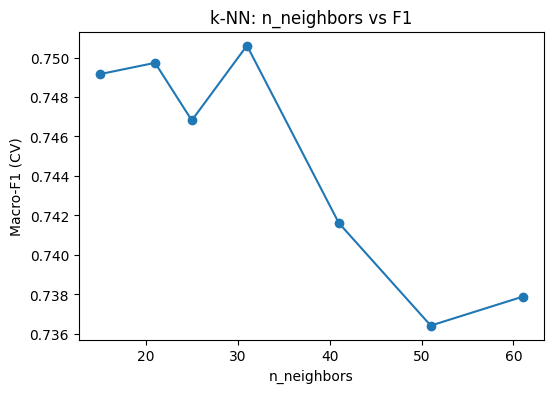

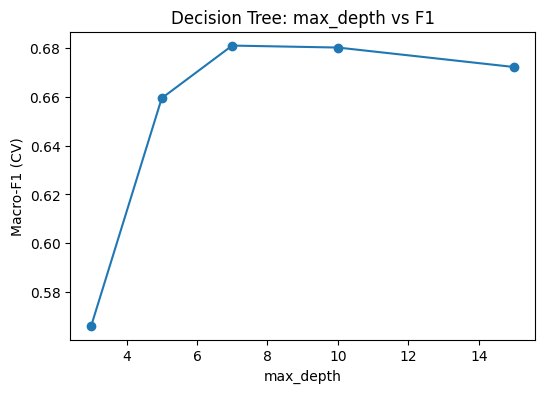

In [41]:
knn_results = pd.DataFrame(grid_knn.cv_results_)
plt.figure(figsize=(6,4))
plt.plot(knn_results['param_classifier__n_neighbors'], knn_results['mean_test_score'], marker='o')
plt.xlabel('n_neighbors'); plt.ylabel('Macro-F1 (CV)'); plt.title('k-NN: n_neighbors vs F1')
plt.savefig('knn_tuning.png', dpi=150); plt.show()

dt_results = pd.DataFrame(grid_dt.cv_results_)
dt_depth_summary = dt_results.groupby('param_classifier__max_depth')['mean_test_score'].mean()
plt.figure(figsize=(6,4))
dt_depth_summary.plot(marker='o')
plt.xlabel('max_depth'); plt.ylabel('Macro-F1 (CV)'); plt.title('Decision Tree: max_depth vs F1')
plt.savefig('dt_tuning.png', dpi=150); plt.show()

### 9. Confusion matrix + classification

              precision    recall  f1-score   support

         low       0.90      0.88      0.89      1981
    moderate       0.78      0.87      0.82      2061
      severe       0.88      0.72      0.79       908

    accuracy                           0.84      4950
   macro avg       0.86      0.82      0.84      4950
weighted avg       0.85      0.84      0.84      4950



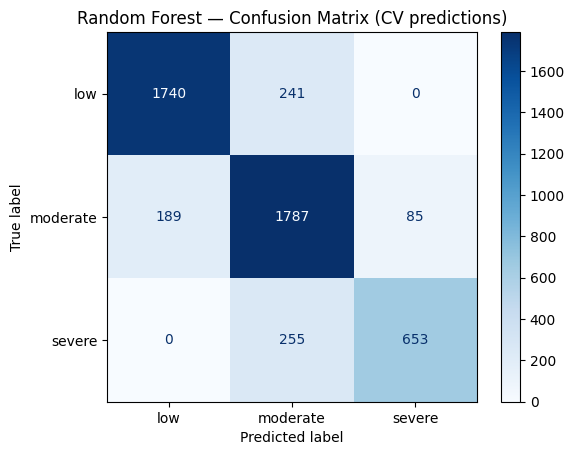

In [42]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

y_pred_cv = cross_val_predict(grid_rf.best_estimator_, X_full, y_full, cv=cv)

print(classification_report(y_full, y_pred_cv))

cm = confusion_matrix(y_full, y_pred_cv, labels=['low','moderate','severe'])
disp = ConfusionMatrixDisplay(cm, display_labels=['low','moderate','severe'])
disp.plot(cmap='Blues')
plt.title('Random Forest — Confusion Matrix (CV predictions)')
plt.savefig('confusion_matrix.png', dpi=150)
plt.show()


### 10. Dimensionality/Feature Importance

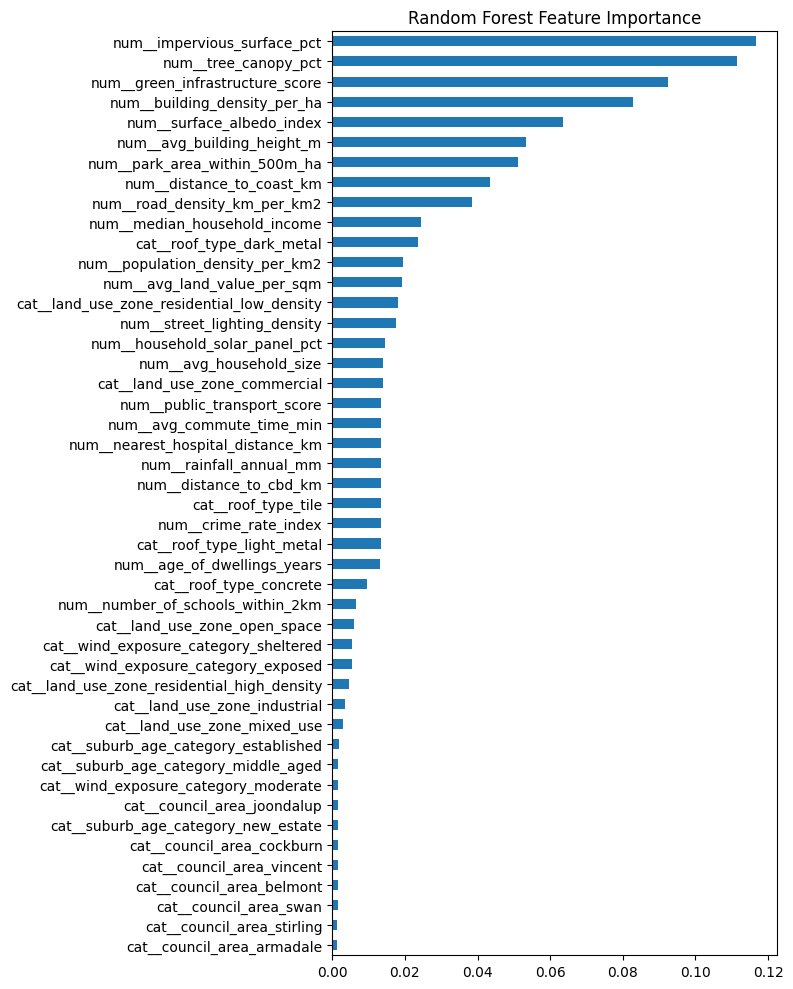

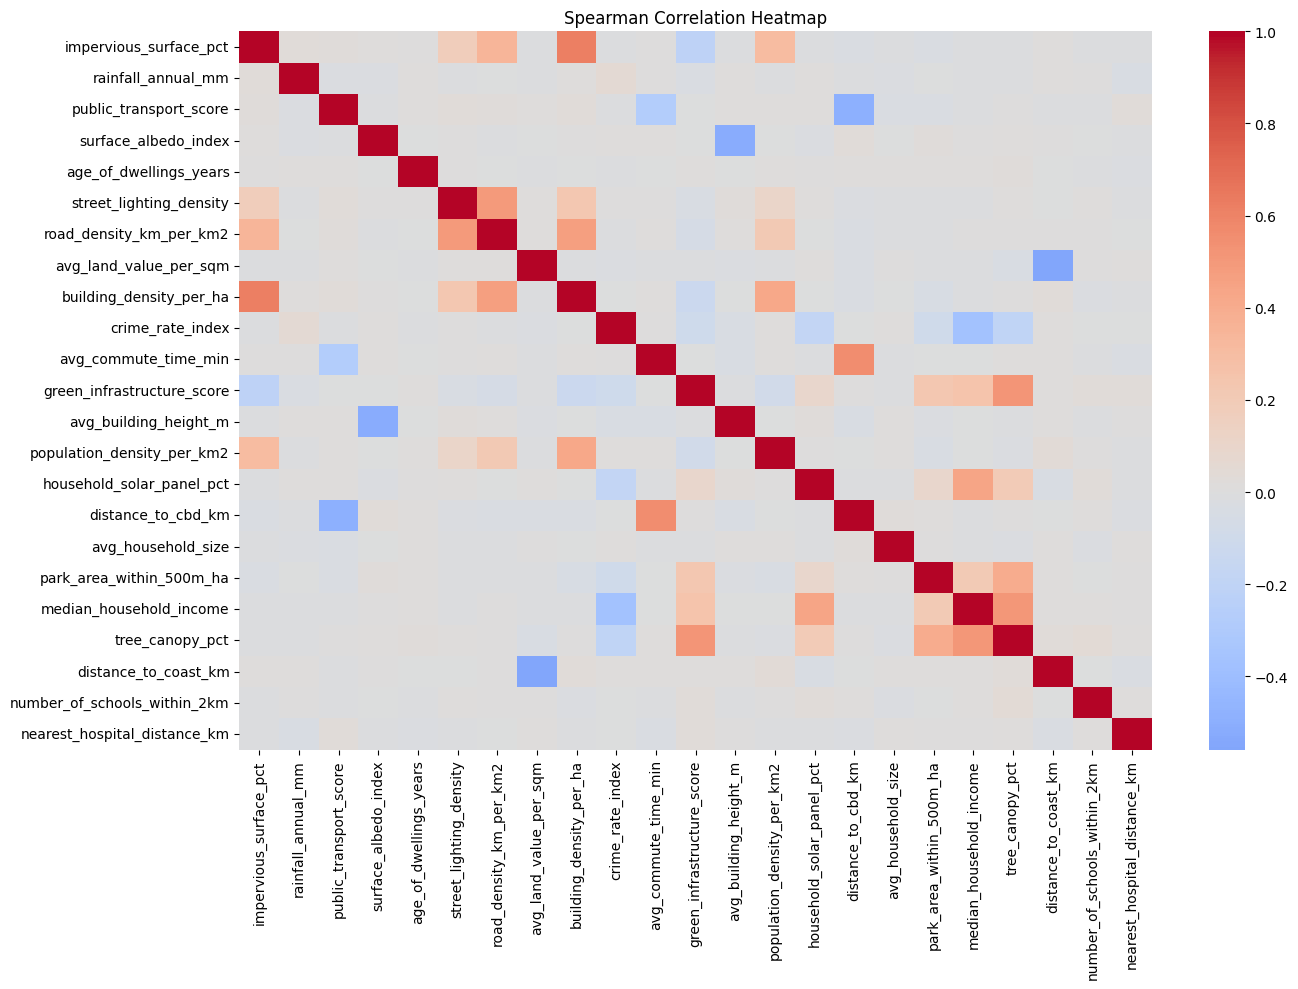

In [43]:
best_rf_pipeline = grid_rf.best_estimator_
feature_names = best_rf_pipeline.named_steps['preprocessor'].get_feature_names_out()
rf_model = best_rf_pipeline.named_steps['classifier']

importances = pd.Series(rf_model.feature_importances_, index=feature_names).sort_values(ascending=False)
plt.figure(figsize=(8,10))
importances.plot(kind='barh')
plt.gca().invert_yaxis()
plt.title('Random Forest Feature Importance')
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=150)
plt.show()

numeric_cols_for_heatmap = [
    'impervious_surface_pct', 'rainfall_annual_mm', 'public_transport_score',
    'surface_albedo_index', 'age_of_dwellings_years', 'street_lighting_density',
    'road_density_km_per_km2', 'avg_land_value_per_sqm', 'building_density_per_ha',
    'crime_rate_index', 'avg_commute_time_min', 'green_infrastructure_score',
    'avg_building_height_m', 'population_density_per_km2', 'household_solar_panel_pct',
    'distance_to_cbd_km', 'avg_household_size', 'park_area_within_500m_ha',
    'median_household_income', 'tree_canopy_pct', 'distance_to_coast_km',
    'number_of_schools_within_2km', 'nearest_hospital_distance_km'
]
plt.figure(figsize=(14,10))
sns.heatmap(X_full[numeric_cols_for_heatmap].corr(method='spearman'), cmap='coolwarm', center=0)
plt.title('Spearman Correlation Heatmap')
plt.tight_layout()
plt.savefig('spearman_heatmap.png', dpi=150)
plt.show()

### 11. Final prediction on unseen data

In [44]:
best_rf_final = grid_rf.best_estimator_   
best_knn_final = grid_knn.best_estimator_

pred_rf = best_rf_final.predict(X_unseen_full)
pred_knn = best_knn_final.predict(X_unseen_full)
print(pred_rf[:10])
print(pred_knn[:10])

['moderate' 'low' 'moderate' 'severe' 'moderate' 'low' 'low' 'severe'
 'low' 'low']
['low' 'low' 'moderate' 'moderate' 'low' 'low' 'low' 'severe' 'moderate'
 'low']


### 12. Export Predictions
Save predictions to a predictions CSV in the required format. Report the CV macro-F1 as the estimated performance on unseen data.

In [45]:
output_name = "uhi"

answers = pd.DataFrame({
    'index': df_unseen['index'],
    'Predict1': pred_rf,
    'Predict2': pred_knn
})
answers.to_csv(f'predictions_{output_name}.csv', index=False)
print(answers.shape)
answers.head(10)

(500, 3)


,index,Predict1,Predict2
0,5000,moderate,low
1,5001,low,low
2,5002,moderate,moderate
3,5003,severe,moderate
4,5004,moderate,low
5,5005,low,low
6,5006,low,low
7,5007,severe,severe
8,5008,low,moderate
9,5009,low,low


In [46]:
X_full.shape, y_full.shape, X_unseen_full.shape

((4950, 31), (4950,), (500, 31))

In [47]:
X_cleaned = add_features.fit_transform(X_full)
print(preprocessor.fit_transform(X_cleaned).shape)

(4950, 46)
